In [1]:
from dataclasses import dataclass, asdict, replace
from pathlib import Path
import hashlib
import json
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, MultipleLocator
from IPython.display import display

%matplotlib inline

In [ ]:
def find_pipeline_root(start=None):
    """Find the pipeline from the notebook, pipeline, or enclosing workspace folder."""
    start = Path(start or Path.cwd()).resolve()
    for parent in (start, *start.parents):
        for candidate in (parent, parent / "DBH-pipeline-whole"):
            result_dir = candidate / "output" / "DBHResults"
            if all((result_dir / method).is_dir() for method in ("MobileSAMv2", "SAM3")):
                return candidate
    raise FileNotFoundError(
        "Cannot locate DBH-pipeline-whole. Start Jupyter from its visualization folder, "
        "or replace PIPELINE_ROOT = find_pipeline_root() with your pipeline folder path."
    )


PIPELINE_ROOT = find_pipeline_root()
DATA_DIR = PIPELINE_ROOT / "output" / "DBHResults"
OUTPUT_DIR = PIPELINE_ROOT / "output" / "visualization"

ID_COL = "uniqueName"
TRUE_COL = "dbhCaliper_cm"
EST_COL = "dbhSAM_UV_cm"

@dataclass(frozen=True)
class ProcessingOptions:
    reference_decimals: int | None = None
    error_decimals: int | None = None
    std_ddof: int = 0  # Population SD, matching np.std in the original notebook.

@dataclass(frozen=True)
class PlotStyle:
    figsize: tuple = (12, 12)
    font_size: float = 54
    dpi: int = 300
    formats: tuple = ("png", "pdf")
    color: str = "#2459A6"
    highlight_color: str = "#C83E3E"
    notch: bool = True
    show_fit: bool = False  # Display the fitted line described by R².
    annotate_stats: bool = False

PROCESSING = ProcessingOptions()
STYLE = PlotStyle()
SHOW_FIGURES = True
INCLUDE_RAW_DIAGNOSTICS = False
# Optional: set a separate geometry CSV path and enable the flag above.
RAW_NATURAL_CSV = None

print(f"Input folder: {DATA_DIR}")
print(f"Output folder: {OUTPUT_DIR}")


Input folder: C:\Users\yinzh\OneDrive\桌面\dataDBH\DBH-pipeline-whole\output\DBHResults
Output folder: C:\Users\yinzh\OneDrive\桌面\dataDBH\DBH-pipeline-whole\visualization\outputs


## 2. Five analysis views


In [3]:
MOBILE_RESTORED_IDS = (
    "A4DA4E04-3617-4EF8-923B-DCA3ACD3F182-240502122808",
    "4E9A883C-8982-4C9F-933E-8C6BEF5BCF9B-240502113028",
)

@dataclass(frozen=True)
class CaseConfig:
    case_id: str
    method: str
    dataset: str
    csv_path: Path
    group_edges: tuple
    exclude_ids: tuple = ()
    highlight_ids: tuple = ()
    flag_abs_error_cm: float = 5.0
    drop_abs_error_ge_cm: float | None = None
    drop_abs_error_gt_cm: float | None = None
    scatter_limits: tuple = (0, 70)
    box_limits: tuple = (-4, 4)

    @property
    def title(self):
        return f"{self.method} · {self.dataset}"

PLOT_EDGES = (0, 33, 39, np.inf)
NATURAL_EDGES = (0, 33, 42, np.inf)

CASES = [
    CaseConfig(
        "mobilesamv2_natural_whole", "MobileSAMv2", "Natural: all data",
        DATA_DIR / "MobileSAMv2" / "results_MobileSAMv2_natural.csv", NATURAL_EDGES,
        highlight_ids=MOBILE_RESTORED_IDS, scatter_limits=(0, 150), box_limits=(-8, 112),
    ),
    CaseConfig(
        "mobilesamv2_natural_cleaned", "MobileSAMv2", "Natural: two outliers excluded",
        DATA_DIR / "MobileSAMv2" / "results_MobileSAMv2_natural.csv", NATURAL_EDGES,
        exclude_ids=MOBILE_RESTORED_IDS, box_limits=(-8, 12),
    ),
    CaseConfig(
        "mobilesamv2_plot", "MobileSAMv2", "Plotted: all data",
        DATA_DIR / "MobileSAMv2" / "results_MobileSAMv2_plot.csv", PLOT_EDGES,
        flag_abs_error_cm=3, box_limits=(-4, 4),
    ),
    CaseConfig(
        "sam3_natural", "SAM3", "Natural: all data",
        DATA_DIR / "SAM3" / "results_SAM3_natural.csv", NATURAL_EDGES,
        box_limits=(-8, 8),
    ),
    CaseConfig(
        "sam3_plot", "SAM3", "Plotted: all data",
        DATA_DIR / "SAM3" / "results_SAM3_plot.csv", PLOT_EDGES,
        flag_abs_error_cm=3, box_limits=(-4, 4),
    ),
]

# Verify the requested two-case rule against the current full production CSVs.
natural_input = pd.read_csv(DATA_DIR / "MobileSAMv2" / "results_MobileSAMv2_natural.csv")
plotted_input = pd.read_csv(DATA_DIR / "MobileSAMv2" / "results_MobileSAMv2_plot.csv")
natural_outliers = set(natural_input.loc[
    natural_input[ID_COL].isin(MOBILE_RESTORED_IDS), ID_COL])
assert natural_outliers == set(MOBILE_RESTORED_IDS)
assert len(natural_input) == 285 and len(plotted_input) == 202

SELECTED_CASES = None
display(pd.DataFrame([
    {"case_id": c.case_id, "method": c.method, "dataset": c.dataset,
     "input_csv": str(c.csv_path.relative_to(PIPELINE_ROOT)),
     "excluded_uniqueNames": c.exclude_ids}
    for c in CASES
]))


,case_id,method,dataset,input_csv,excluded_uniqueNames
0,mobilesamv2_natural_whole,MobileSAMv2,Natural: all data,output\DBHResults\MobileSAMv2\results_MobileSA...,()
1,mobilesamv2_natural_cleaned,MobileSAMv2,Natural: two outliers excluded,output\DBHResults\MobileSAMv2\results_MobileSA...,(A4DA4E04-3617-4EF8-923B-DCA3ACD3F182-24050212...
2,mobilesamv2_plot,MobileSAMv2,Plotted: all data,output\DBHResults\MobileSAMv2\results_MobileSA...,()
3,sam3_natural,SAM3,Natural: all data,output\DBHResults\SAM3\results_SAM3_natural.csv,()
4,sam3_plot,SAM3,Plotted: all data,output\DBHResults\SAM3\results_SAM3_plot.csv,()


## 3. Statistics Analysis

For reference x and estimate y, signed error e = y − x. Positive values mean
overestimation. Use full-precision values for all calculations and exclusions.

- RMSE = sqrt(mean(e²)).
- Signed mean error = mean(e).
- Error SD = sqrt(mean((e − mean(e))²)); population SD, denominator n.

Report the retained count alongside these three metrics. With population SD,
RMSE² = signed mean error² + error SD². Missing metrics for empty groups are undefined.

For each DBH comparison plot, fit an ordinary least-squares straight line with
an intercept, using exactly the retained points shown on the axes:

`fitted estimate = slope × reference + intercept`.

`R² = 1 − sum((estimate − fitted estimate)²) / sum((estimate − mean(estimate))²)`.

The R² annotation describes this fitted line. The dashed 1:1 line remains a
separate reference for perfect DBH agreement. R² is unitless and is undefined
for fewer than two observations or constant reference or estimated DBH. Each
view uses its own outlier exclusions and the plotted values before any optional
rounding of signed errors. The fitted line can be hidden with `show_fit=False`.


In [4]:
def group_labels(edges):
    '''Unambiguous labels for right-closed diameter bins.'''
    return [
        f"> {low:g}" if np.isposinf(high) else
        (f"≤ {high:g}" if low == 0 else f"{low:g} < d ≤ {high:g}")
        for low, high in zip(edges[:-1], edges[1:])
    ]


def load_case(config, options=PROCESSING):
    '''Return retained observations, every input row with flags, and counts.'''
    edges = np.asarray(config.group_edges, dtype=float)
    if (len(edges) < 2 or edges[0] != 0 or not np.isposinf(edges[-1])
            or not np.all(np.diff(edges) > 0)):
        raise ValueError(f"{config.case_id}: group edges must rise from 0 to infinity.")
    if options.std_ddof not in (0, 1):
        raise ValueError("std_ddof must be 0 (population) or 1 (sample).")
    for name in ("flag_abs_error_cm", "drop_abs_error_ge_cm", "drop_abs_error_gt_cm"):
        value = getattr(config, name)
        if value is not None and (not np.isfinite(value) or value <= 0):
            raise ValueError(f"{name} must be a positive finite number or None.")

    frame = pd.read_csv(config.csv_path, dtype={ID_COL: "string"})
    required = {ID_COL, TRUE_COL, EST_COL}
    missing = required.difference(frame.columns)
    if missing:
        raise ValueError(f"{config.csv_path}: missing columns {sorted(missing)}")
    if frame[ID_COL].isna().any() or frame[ID_COL].str.strip().eq("").any():
        raise ValueError(f"{config.csv_path}: missing observation IDs.")
    if frame[ID_COL].duplicated().any():
        raise ValueError(f"{config.csv_path}: duplicate IDs; resolve before evaluation.")

    frame = frame[[ID_COL, TRUE_COL, EST_COL]].copy()
    frame.insert(0, "input_row", np.arange(2, len(frame) + 2))
    frame["reference_input"] = frame[TRUE_COL]
    frame["estimate_input"] = frame[EST_COL]
    for col in (TRUE_COL, EST_COL):
        frame[col] = pd.to_numeric(frame[col], errors="coerce")
    if options.reference_decimals is not None:
        frame[TRUE_COL] = frame[TRUE_COL].round(options.reference_decimals)
    frame["error_cm"] = frame[EST_COL] - frame[TRUE_COL]
    if options.error_decimals is not None:
        frame["error_cm"] = frame["error_cm"].round(options.error_decimals)

    finite = np.isfinite(frame[[TRUE_COL, EST_COL]]).all(axis=1)
    positive_reference = frame[TRUE_COL] > 0
    frame["excluded_by_id"] = frame[ID_COL].isin(config.exclude_ids)
    frame["invalid_pair"] = ~(finite & positive_reference)
    frame["excluded_by_error_cutoff"] = False
    if config.drop_abs_error_ge_cm is not None:
        frame["excluded_by_error_cutoff"] = (
            frame["error_cm"].abs() >= config.drop_abs_error_ge_cm
        )
    if config.drop_abs_error_gt_cm is not None:
        frame["excluded_by_error_cutoff"] |= (
            frame["error_cm"].abs() > config.drop_abs_error_gt_cm
        )
    frame["included"] = ~frame[[
        "excluded_by_id", "invalid_pair", "excluded_by_error_cutoff"
    ]].any(axis=1)
    reason = pd.Series("", index=frame.index, dtype="string")
    for flag, label in (
        (frame["excluded_by_id"], "configured_id"),
        (~finite, "nonfinite_pair"),
        (finite & ~positive_reference, "nonpositive_reference"),
        (frame["excluded_by_error_cutoff"], "error_cutoff"),
    ):
        reason.loc[flag] = reason.loc[flag] + label + ";"
    frame["exclusion_reason"] = reason.str.rstrip(";")
    frame["large_error_flag"] = False
    if config.flag_abs_error_cm is not None:
        frame["large_error_flag"] = frame["error_cm"].abs() >= config.flag_abs_error_cm
    frame["highlighted"] = frame[ID_COL].isin(config.highlight_ids)
    frame["diameter_group"] = pd.cut(
        frame[TRUE_COL], bins=edges, labels=group_labels(edges), right=True,
    )
    frame["relative_error_pct"] = np.nan
    valid = finite & positive_reference
    frame.loc[valid, "relative_error_pct"] = (
        100 * frame.loc[valid, "error_cm"] / frame.loc[valid, TRUE_COL]
    )
    frame.insert(0, "case_id", config.case_id)
    retained = frame.loc[frame["included"]].copy()
    absent = sorted(set(config.exclude_ids).difference(frame[ID_COL]))
    counts = {
        "case_id": config.case_id, "method": config.method, "dataset": config.dataset,
        "source_csv": str(config.csv_path.resolve()),
        "n_input": len(frame), "n_retained": len(retained),
        "n_excluded_total": int((~frame["included"]).sum()),
        # Flag counts may overlap; only n_excluded_total counts distinct rows.
        "n_excluded_by_id": int(frame["excluded_by_id"].sum()),
        "n_invalid_pair": int(frame["invalid_pair"].sum()),
        "n_error_cutoff": int(frame["excluded_by_error_cutoff"].sum()),
        "n_retained_large_errors": int(retained["large_error_flag"].sum()),
        "configured_exclusion_ids_absent": ";".join(absent),
    }
    return retained, frame, counts


def fit_linear_regression(reference, estimate):
    """Return OLS slope, intercept and R² for estimated versus reference DBH."""
    reference = np.asarray(reference, dtype=float)
    estimate = np.asarray(estimate, dtype=float)
    if reference.ndim != 1 or reference.shape != estimate.shape:
        raise ValueError("R² requires matching one-dimensional observation arrays.")
    if len(reference) < 2 or not (np.isfinite(reference).all() and np.isfinite(estimate).all()):
        return np.nan, np.nan, np.nan
    centered_reference = reference - reference.mean()
    centered_estimate = estimate - estimate.mean()
    reference_variation = float(np.dot(centered_reference, centered_reference))
    if reference_variation == 0:
        return np.nan, np.nan, np.nan
    slope = float(np.dot(centered_reference, centered_estimate) / reference_variation)
    intercept = float(estimate.mean() - slope * reference.mean())
    estimate_variation = float(np.dot(centered_estimate, centered_estimate))
    residual = centered_estimate - slope * centered_reference
    r2 = (1.0 - float(np.dot(residual, residual)) / estimate_variation
          if estimate_variation > 0 else np.nan)
    return slope, intercept, r2


def error_metrics(frame, options=PROCESSING):
    """Error statistics and fitted-line R² from the same retained observations."""
    error = frame["error_cm"].to_numpy(dtype=float)
    n = len(error)
    return {
        "n": n, "std_ddof": options.std_ddof,
        "r2": fit_linear_regression(frame[TRUE_COL], frame[EST_COL])[2],
        "rmse_cm": float(np.sqrt(np.mean(error**2))) if n else np.nan,
        "signed_mean_error_cm": float(np.mean(error)) if n else np.nan,
        "error_std_cm": float(np.std(error, ddof=options.std_ddof))
                        if n > options.std_ddof else np.nan,
    }


def summarize_case(frame, config, options=PROCESSING):
    '''One overall row plus one row for every configured diameter group.'''
    rows = []
    subsets = [("overall", "Overall", frame)] + [
        ("diameter_group", label, frame.loc[frame["diameter_group"] == label])
        for label in group_labels(config.group_edges)
    ]
    for scope, group, subset in subsets:
        rows.append({
            "case_id": config.case_id, "method": config.method, "dataset": config.dataset,
            "scope": scope, "group": group,
            **error_metrics(subset, options),
        })
    return pd.DataFrame(rows)


## 4. Plots

In [5]:
def plot_rc(style):
    return {
        "font.family": "serif", "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
        "mathtext.fontset": "cm", "text.usetex": False,
        "font.size": style.font_size, "axes.titlesize": style.font_size,
        "axes.labelsize": style.font_size,
        "xtick.labelsize": style.font_size - 8, "ytick.labelsize": style.font_size - 8,
        "axes.spines.top": False, "axes.spines.right": False,
        "figure.dpi": 110, "pdf.fonttype": 42,
    }


def expanded_limits(values, preferred):
    '''Keep preferred limits unless expansion is needed to show every point.'''
    low, high = preferred
    if not np.isfinite([low, high]).all() or low >= high:
        raise ValueError("Plot limits must be finite and increasing.")
    values = np.asarray(values, dtype=float)
    if values.size:
        padding = 0.04 * max(float(np.ptp(values)), high - low, 1)
        if values.min() - padding < low:
            low = float(values.min() - padding)
        if values.max() + padding > high:
            high = float(values.max() + padding)
    return low, high


def plot_boxplot(frame, config, style=STYLE):
    labels = group_labels(config.group_edges)
    groups = [frame.loc[frame["diameter_group"] == label, "error_cm"].to_numpy()
              for label in labels]
    with plt.rc_context(plot_rc(style)):
        fig, ax = plt.subplots(figsize=style.figsize, layout="constrained")
        populated = [(i + 1, values) for i, values in enumerate(groups) if len(values)]
        if populated:
            positions, values = zip(*populated)
            ax.boxplot(
                values, positions=positions, widths=0.55, notch=style.notch,
                patch_artist=False,
                boxprops={"color": style.color, "linewidth": 1.8},
                whiskerprops={"color": "#333333", "linewidth": 1.5},
                capprops={"color": "#333333", "linewidth": 1.5},
                medianprops={"color": style.highlight_color, "linewidth": 1.8},
                flierprops={"marker": "o", "markersize": 15,
                            "markerfacecolor": style.highlight_color,
                            "markeredgecolor": style.highlight_color},
            )
        ax.axhline(0, color="#777777", linewidth=1, linestyle="--", zorder=0)
        ax.set_xticks(range(1, len(labels) + 1),
                      [label.replace(" < d ≤ ", "–") for label in labels])
        # for position, values in enumerate(groups, 1):
        #     ax.annotate(f"(n = {len(values)})", xy=(position, 0),
        #                 xycoords=("data", "axes fraction"),
        #                 xytext=(0, -style.font_size * 1.25), textcoords="offset points",
        #                 ha="center", va="top", fontsize=style.font_size - 24,
        #                 annotation_clip=False)
        ax.tick_params(axis="both", labelsize=style.font_size)
        ax.set_xlim(0.4, len(labels) + 0.6)
        # Include notch extents as well as observations when avoiding clipping.
        visible = list(frame["error_cm"])
        for values in groups:
            if len(values):
                q1, median, q3 = np.percentile(values, [25, 50, 75])
                delta = 1.57 * (q3 - q1) / np.sqrt(len(values)) if style.notch else 0
                visible.extend([median - delta, median + delta])
        ax.set_ylim(*expanded_limits(visible, config.box_limits))
        ax.yaxis.set_major_locator(MaxNLocator(nbins=4 if config.box_limits == (-4, 4) else 7))
        ax.set_xlabel(r"$d_{\mathrm{true}}$ (cm)", labelpad=style.font_size * 1.2)
        ax.set_ylabel(r"$e_{\mathrm{dbh}}$ (cm)")
        # ax.set_title(config.title.replace(" · ", "\n").replace(": two", ":\ntwo"), pad=15)
        ax.set_title(config.method, pad=15, fontsize=54)
        ax.set_axisbelow(True)
        ax.yaxis.grid(True, color="#E5E5E5", linewidth=0.7)
        return fig


def plot_scatter(frame, config, stats, style=STYLE):
    x = frame[TRUE_COL].to_numpy(dtype=float)
    y = frame[EST_COL].to_numpy(dtype=float)
    highlighted = frame["highlighted"].to_numpy(dtype=bool)
    with plt.rc_context(plot_rc(style)):
        fig, ax = plt.subplots(figsize=style.figsize, layout="constrained")
        ax.scatter(x[~highlighted], y[~highlighted], s=150, color=style.color,
                   edgecolors="white", linewidths=0.4, alpha=0.85, label="Estimated", zorder=3)
        if highlighted.any():
            ax.scatter(x[highlighted], y[highlighted], s=60, color=style.highlight_color,
                       edgecolors="black", linewidths=0.5, label="Outliers", zorder=4)
        limits = expanded_limits(np.r_[x, y], config.scatter_limits)
        ax.plot(limits, limits, "--", color=style.highlight_color, linewidth=1.7,
                label=r"$d_{\mathrm{est}} = d_{\mathrm{true}}$", zorder=5)
        slope, intercept, _ = fit_linear_regression(x, y)
        if style.show_fit and np.isfinite(slope):
            fit_x = np.linspace(x.min(), x.max(), 100)
            ax.plot(fit_x, slope * fit_x + intercept, color="#A57015", linewidth=1.6,
                    label="Linear fit")
        ax.set(xlim=limits, ylim=limits)
        ax.set_aspect("equal", adjustable="box")
        ax.xaxis.set_major_locator(MaxNLocator(nbins=7))
        ax.yaxis.set_major_locator(MaxNLocator(nbins=7))
        ax.set_xlabel(r"$d_{\mathrm{true}}$ (cm)", fontsize=style.font_size + 8)
        ax.set_ylabel(r"$d_{\mathrm{est}}$ (cm)", fontsize=style.font_size + 8)
        # ax.set_title(config.title.replace(" · ", "\n").replace(": two", ":\ntwo"), pad=15,
                    #  fontsize=style.font_size - 8 if config.dataset.startswith("Plotted:") else style.font_size)
        ax.set_title(config.method, pad=15, fontsize=54)
        ax.grid(True, color="#E5E5E5", linewidth=0.7)
        legend_options = {"bbox_to_anchor": (0.01, 0.84)} if highlighted.any() else {}
        ax.legend(loc="upper left", fontsize=style.font_size - 24, frameon=False, **legend_options)
        overall = stats.loc[stats["scope"] == "overall"].iloc[0]
        r2 = overall["r2"]
        annotation = rf"$R^2 = {r2:.3f}$" if np.isfinite(r2) else r"$R^2$ undefined"
        if style.annotate_stats:
            annotation += (
                f"\nn = {len(frame)}\n"
                f"RMSE = {overall['rmse_cm']:.3f} cm\n"
                f"Signed mean = {overall['signed_mean_error_cm']:+.3f} cm\n"
                f"Error SD = {overall['error_std_cm']:.3f} cm"
            )
        ax.text(0.97, 0.04, annotation, transform=ax.transAxes, ha="right", va="bottom",
                fontsize=style.font_size - 24,
                bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9})
        return fig


def save_figure(fig, destination, style=STYLE, show=True):
    destination.parent.mkdir(parents=True, exist_ok=True)
    paths = []
    try:
        for extension in style.formats:
            path = destination.with_suffix(f".{extension}")
            # Open in write-only mode to avoid Windows PNG overwrite errors.
            with path.open("wb") as output:
                fig.savefig(output, format=extension, dpi=style.dpi,
                            bbox_inches="tight", pad_inches=0.12)
            paths.append(path)
        if show:
            display(fig)
    finally:
        plt.close(fig)
    return paths


## 5. Batch execution


In [ ]:
def plot_raw_diagnostics(csv_path, output_dir, style=STYLE, show=True):
    if csv_path is None:
        warnings.warn("Raw camera-position plots skipped: set RAW_NATURAL_CSV first.")
        return pd.DataFrame()
    csv_path = Path(csv_path)
    if not csv_path.is_file():
        warnings.warn(f"Raw camera-position plots skipped: file not found: {csv_path}")
        return pd.DataFrame()
    raw = pd.read_csv(csv_path)
    specs = [
        ("cameraDistance_cm", "camera_distance", r"Camera distance, $\tilde{p}$ (cm)"),
        ("leftRightAngleDegree", "theta_z", r"Left/right angle, $\theta_z$ (°)"),
        ("upDownAngelDegree", "theta_x", r"Up/down angle, $\theta_x$ (°)"),
    ]
    required = {TRUE_COL, *(item[0] for item in specs)}
    if not required.issubset(raw.columns):
        raise ValueError(f"Raw diagnostics missing columns: {sorted(required - set(raw.columns))}")
    records = []
    for column, stem, ylabel in specs:
        pairs = raw[[TRUE_COL, column]].apply(pd.to_numeric, errors="coerce")
        valid = np.isfinite(pairs).all(axis=1) & (pairs[TRUE_COL] > 0)
        pairs = pairs.loc[valid]
        with plt.rc_context(plot_rc(style)):
            fig, ax = plt.subplots(figsize=(9, 5.5), layout="constrained")
            ax.scatter(pairs[TRUE_COL], pairs[column], s=150, color=style.color,
                       edgecolors="white", linewidths=0.3, alpha=0.8)
            ax.set_xlabel(r"Reference DBH, $d_{\mathrm{true}}$ (cm)")
            ax.set_ylabel(ylabel)
            ax.set_title(f"Natural acquisition geometry (n = {len(pairs)})", pad=12)
            ax.grid(True, color="#E5E5E5", linewidth=0.7)
            ax.set_axisbelow(True)
            ax.margins(0.06)
        save_figure(fig, output_dir / "raw_natural" / stem, style, show)
        records.append({"variable": column, "n_input": len(raw), "n_plotted": len(pairs),
                        "n_invalid": int((~valid).sum()), "source_csv": str(csv_path.resolve())})
    counts = pd.DataFrame(records)
    counts.to_csv(output_dir / "raw_natural" / "diagnostic_counts.csv", index=False)
    return counts


def run_case(config, output_dir=OUTPUT_DIR, options=PROCESSING, style=STYLE, show=True):
    '''One entry point for any method/dataset configuration.'''
    frame, row_audit, counts = load_case(config, options)
    stats = summarize_case(frame, config, options)
    destination = Path(output_dir) / config.case_id
    destination.mkdir(parents=True, exist_ok=True)
    stats.to_csv(destination / "statistics.csv", index=False, encoding="utf-8-sig")
    row_audit.to_csv(destination / "observations.csv", index=False, encoding="utf-8-sig")
    figures = []
    figures += save_figure(plot_boxplot(frame, config, style),
                           destination / "error_boxplot", style, show)
    figures += save_figure(plot_scatter(frame, config, stats, style),
                           destination / "dbh_scatter", style, show)
    print(f"{config.title}: {len(frame)}/{counts['n_input']} rows retained")
    return {"data": frame, "statistics": stats, "observations": row_audit,
            "counts": counts, "figures": figures}


def json_ready(value):
    '''Convert settings to portable strict JSON (infinity represented as text).'''
    if isinstance(value, Path):
        return str(value.resolve())
    if isinstance(value, dict):
        return {key: json_ready(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_ready(item) for item in value]
    if isinstance(value, float) and not np.isfinite(value):
        return str(value)
    return value


def run_all_cases(cases=CASES, output_dir=OUTPUT_DIR, selected=None,
                  options=PROCESSING, style=STYLE, show=True,
                  include_raw_diagnostics=False, raw_csv=RAW_NATURAL_CSV):
    '''Run all cases (or selected IDs), save combined CSVs, return results in memory.'''
    ids = [case.case_id for case in cases]
    if len(ids) != len(set(ids)):
        raise ValueError("Every case_id must be unique to prevent output overwrites.")
    if isinstance(selected, str):
        selected = [selected]
    if selected is not None and set(selected).difference(ids):
        raise ValueError(f"Unknown case IDs: {sorted(set(selected).difference(ids))}")
    chosen = [case for case in cases if selected is None or case.case_id in selected]
    if not chosen:
        raise ValueError("Select at least one case.")
    missing = [str(case.csv_path) for case in chosen if not case.csv_path.is_file()]
    if missing:
        raise FileNotFoundError("Update DATA_DIR / case csv_path. Missing: " + "; ".join(missing))
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    results = {case.case_id: run_case(case, output_dir, options, style, show) for case in chosen}
    statistics = pd.concat([result["statistics"] for result in results.values()], ignore_index=True)
    # overall = statistics.loc[statistics["scope"] == "overall"].reset_index(drop=True)
    # counts = pd.DataFrame([result["counts"] for result in results.values()])
    # A subset run gets distinct aggregate filenames, preserving the all-case report.
    prefix = "all_cases" if len(chosen) == len(cases) else "selected_cases"
    statistics.to_csv(output_dir / f"{prefix}_statistics.csv", index=False, encoding="utf-8-sig")
    overall.to_csv(output_dir / f"{prefix}_overall.csv", index=False, encoding="utf-8-sig")
    counts.to_csv(output_dir / f"{prefix}_counts.csv", index=False, encoding="utf-8-sig")
    raw_counts = (plot_raw_diagnostics(raw_csv, output_dir, style, show)
                  if include_raw_diagnostics else pd.DataFrame())
    input_paths = {case.csv_path.resolve() for case in chosen}
    if include_raw_diagnostics and raw_csv is not None and Path(raw_csv).is_file():
        input_paths.add(Path(raw_csv).resolve())
    manifest = {
        "source_notebook": PIPELINE_ROOT / "visualization" / "fusedSAM_visualization_clean.ipynb",
        "cases": [asdict(case) for case in chosen], "processing": asdict(options),
        "style": asdict(style), "output_dir": output_dir.resolve(),
        "raw_diagnostics_requested": include_raw_diagnostics,
        "input_sha256": {str(path): hashlib.sha256(path.read_bytes()).hexdigest()
                         for path in sorted(input_paths)},
        "versions": {"python": platform.python_version(), "numpy": np.__version__,
                     "pandas": pd.__version__, "matplotlib": matplotlib.__version__},
        "error_definition": "estimate - reference, then optional error rounding",
        "reported_metrics": ["rmse_cm", "signed_mean_error_cm", "error_std_cm", "r2"],
        "r2_definition": "OLS fitted-line R² with intercept: 1 - sum((estimate - fitted_estimate)^2) / sum((estimate - mean(estimate))^2); uses retained plotted pairs",
        "std_definition": "Population SD of signed errors; denominator n (ddof=0)",
        "filtered_view_rule": "Natural MobileSAMv2 only: exclude the configured uniqueNames in MOBILE_RESTORED_IDS; all-data CSVs remain intact",
    }
    (output_dir / f"{prefix}_configuration.json").write_text(
        json.dumps(json_ready(manifest), indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8"
    )
    print(f"\nSaved {len(chosen)} cases to {output_dir.resolve()}")
    return {"cases": results, "statistics": statistics, "overall": overall,
            "counts": counts, "raw_counts": raw_counts}


## 6. Generate pipeline

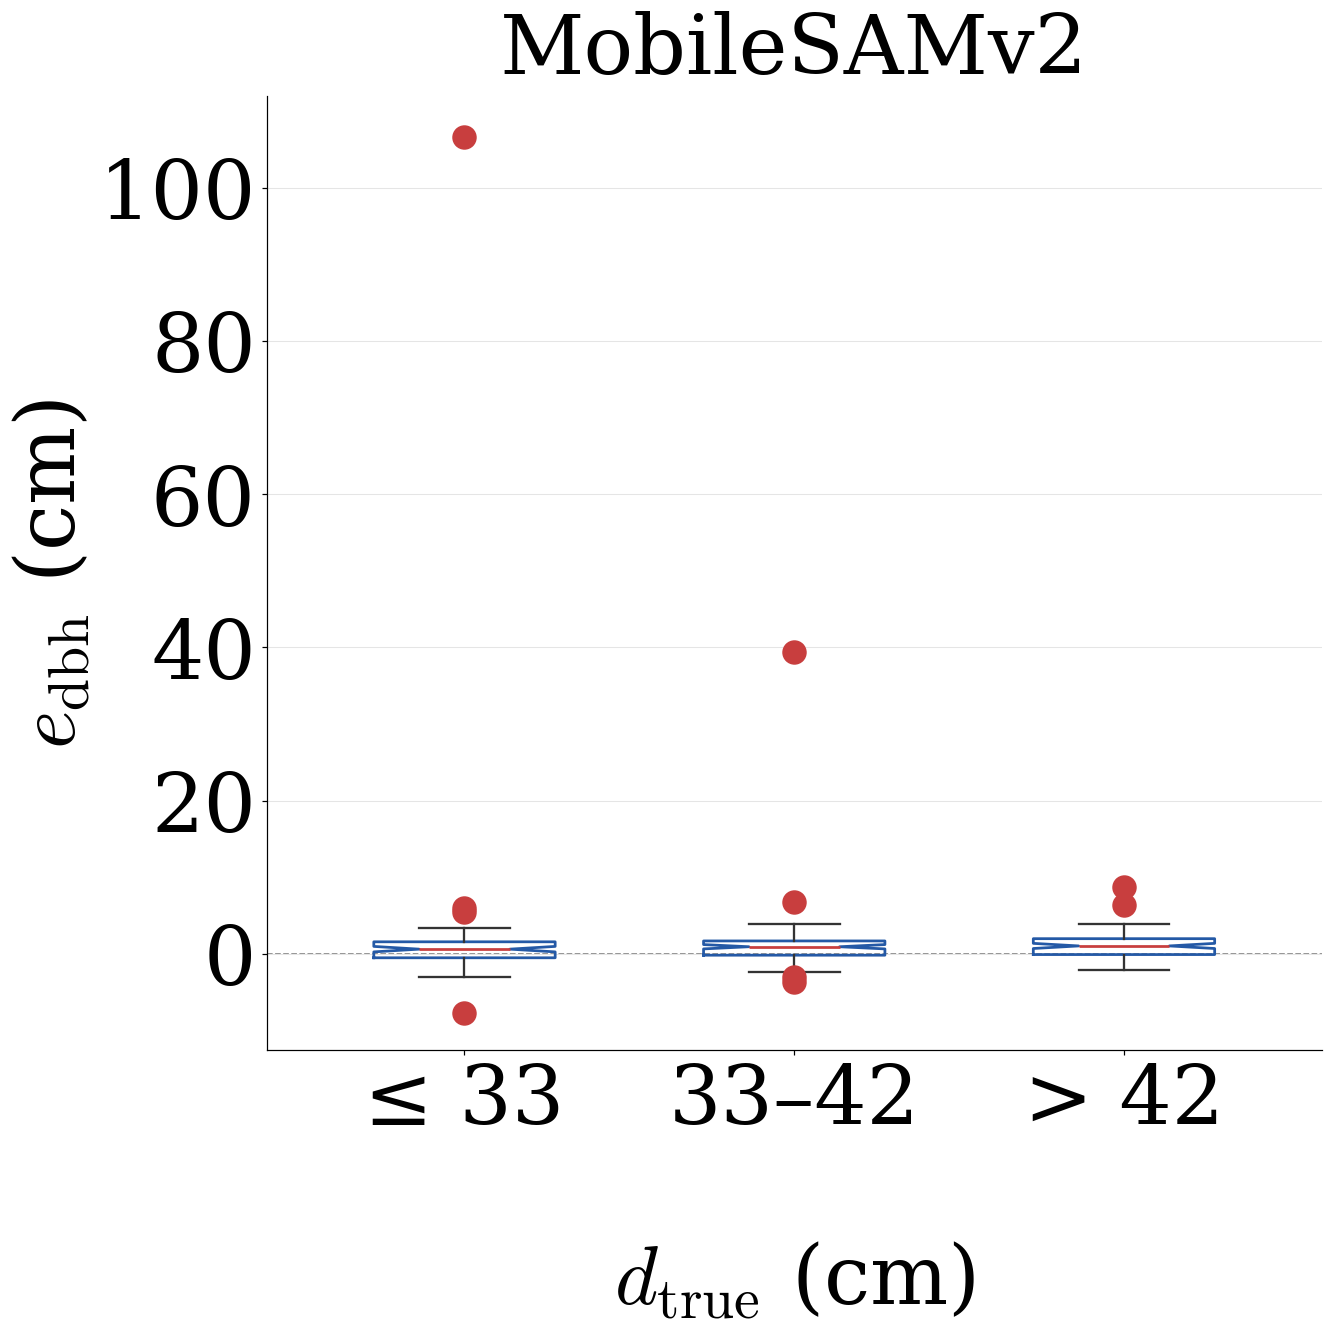

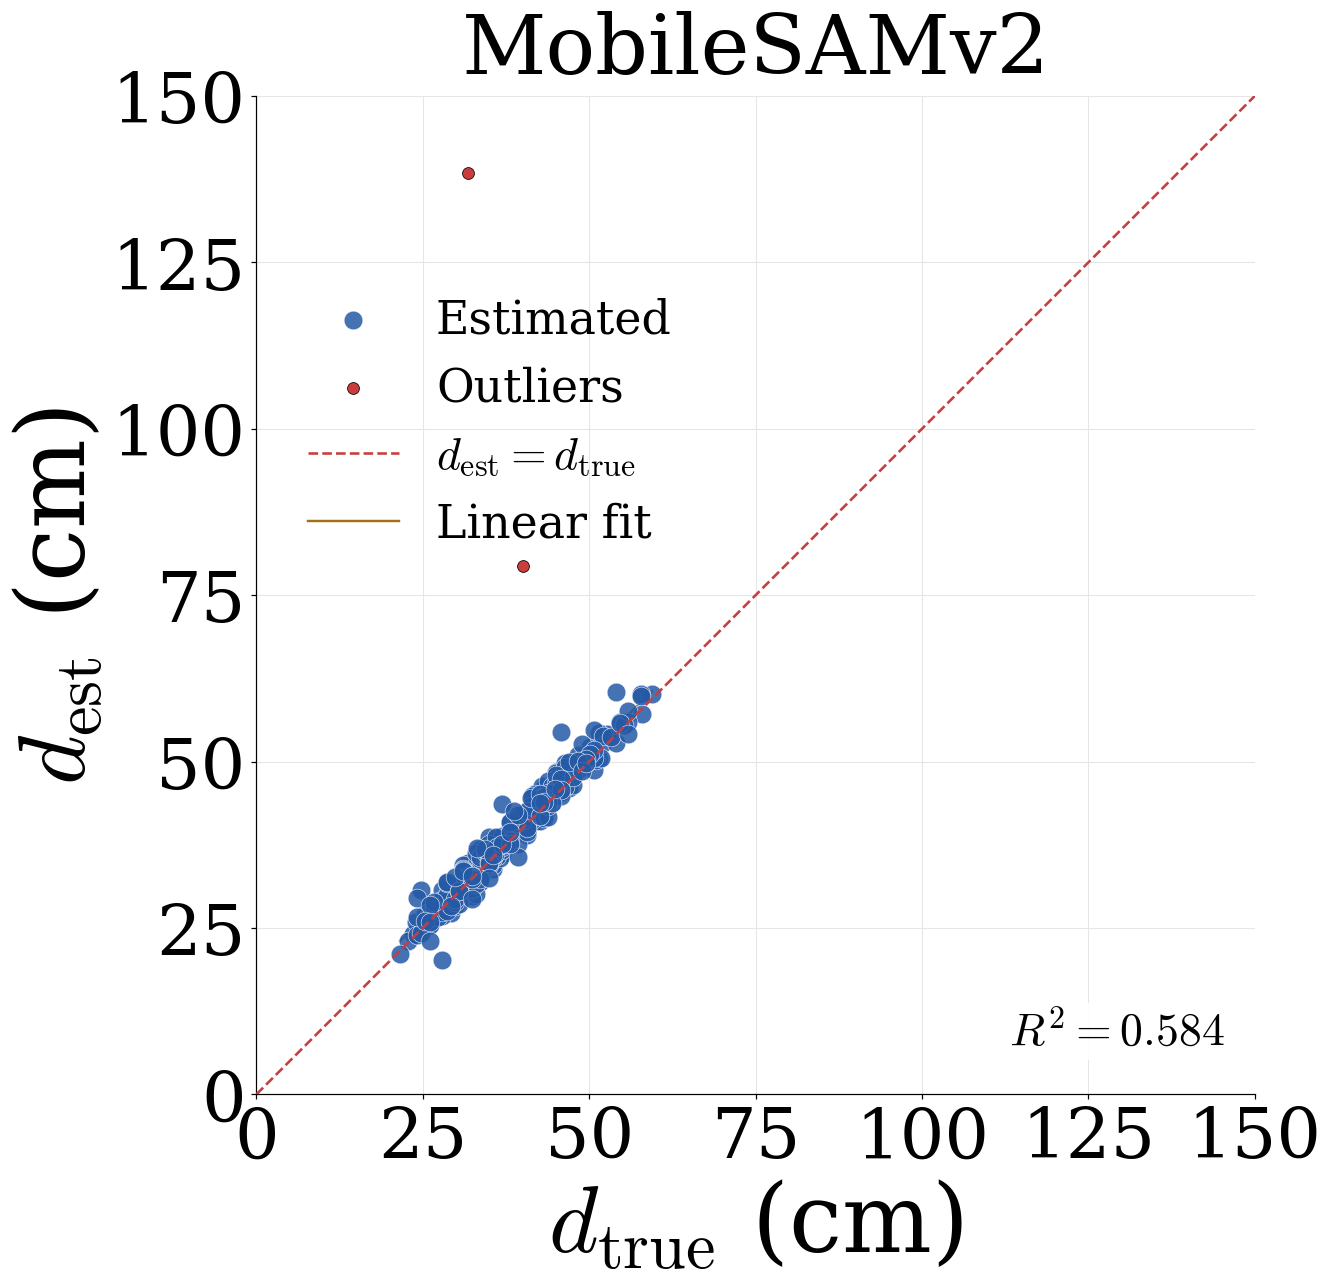

MobileSAMv2 · Natural: all data: 285/285 rows retained


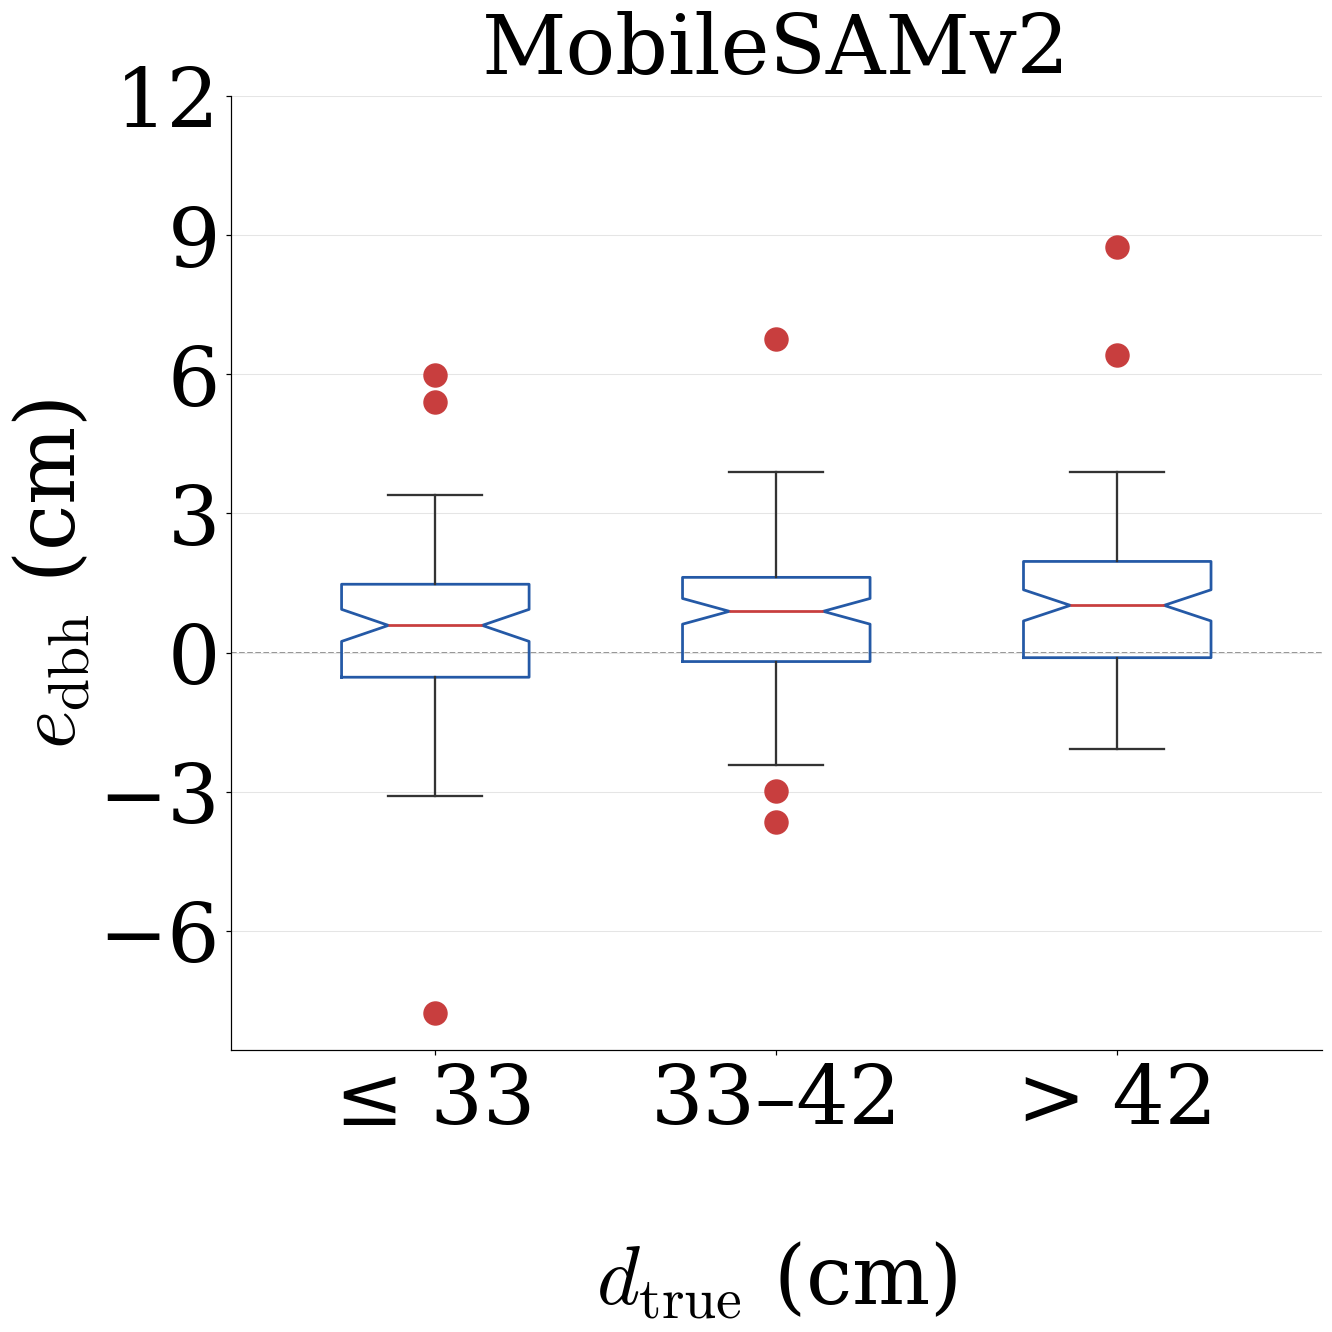

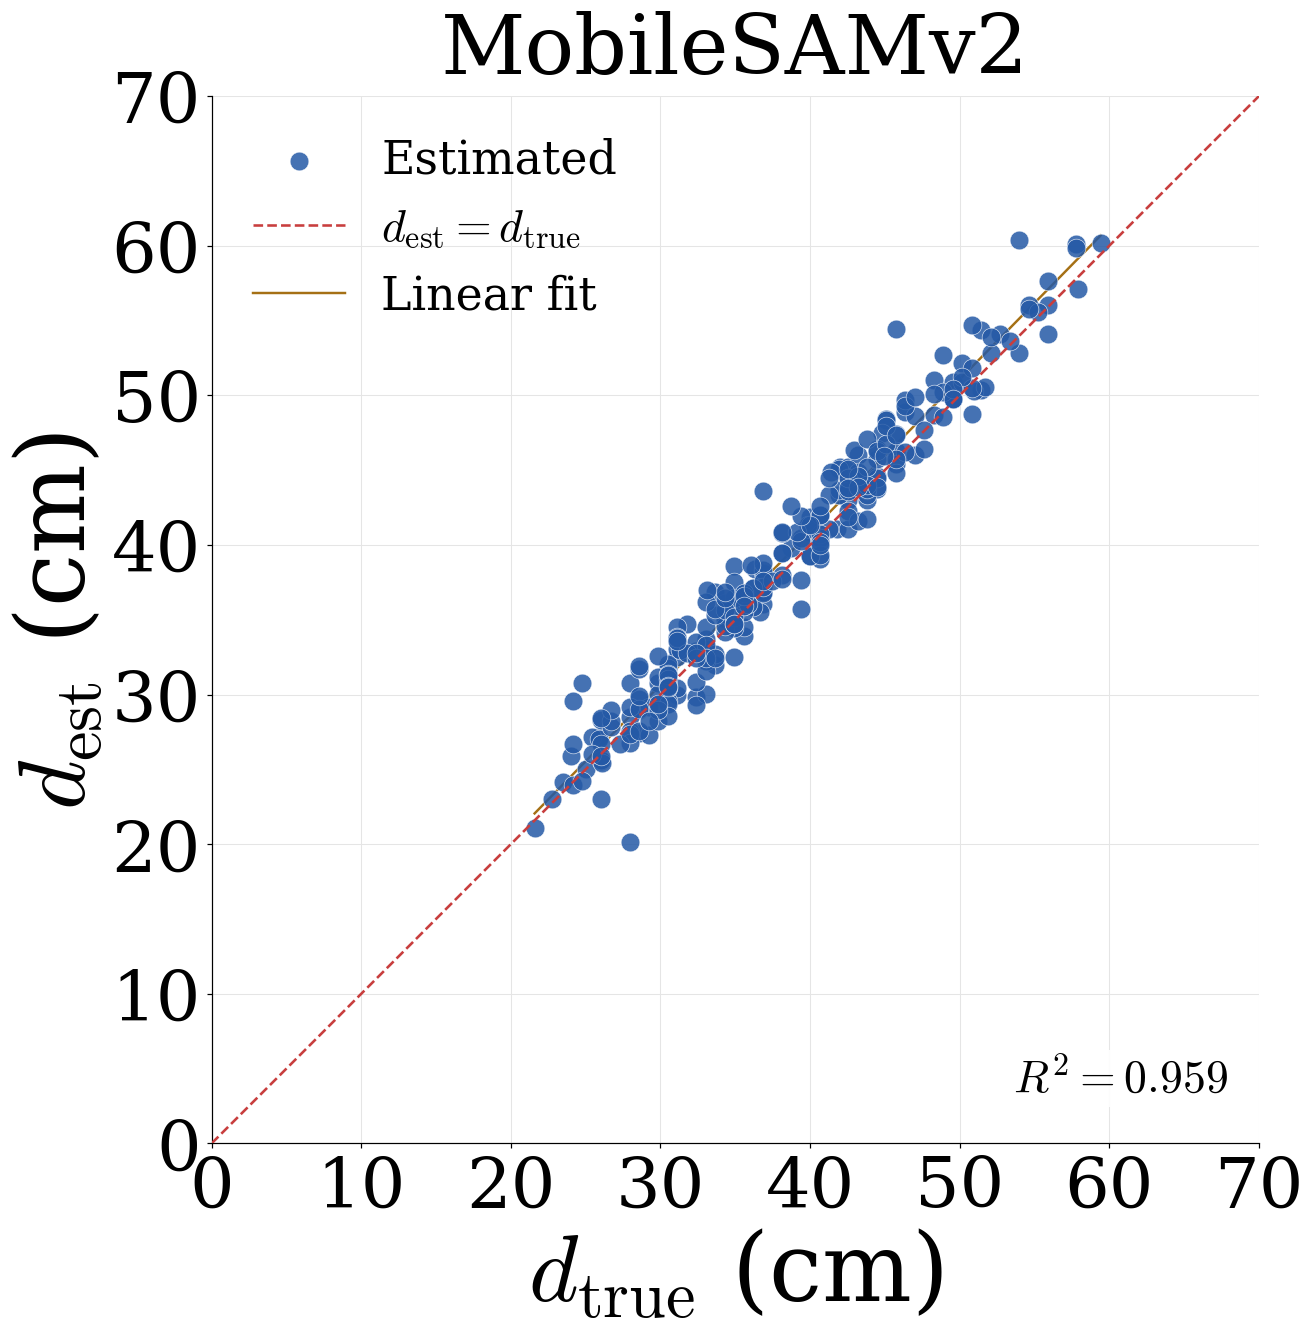

MobileSAMv2 · Natural: two outliers excluded: 283/285 rows retained


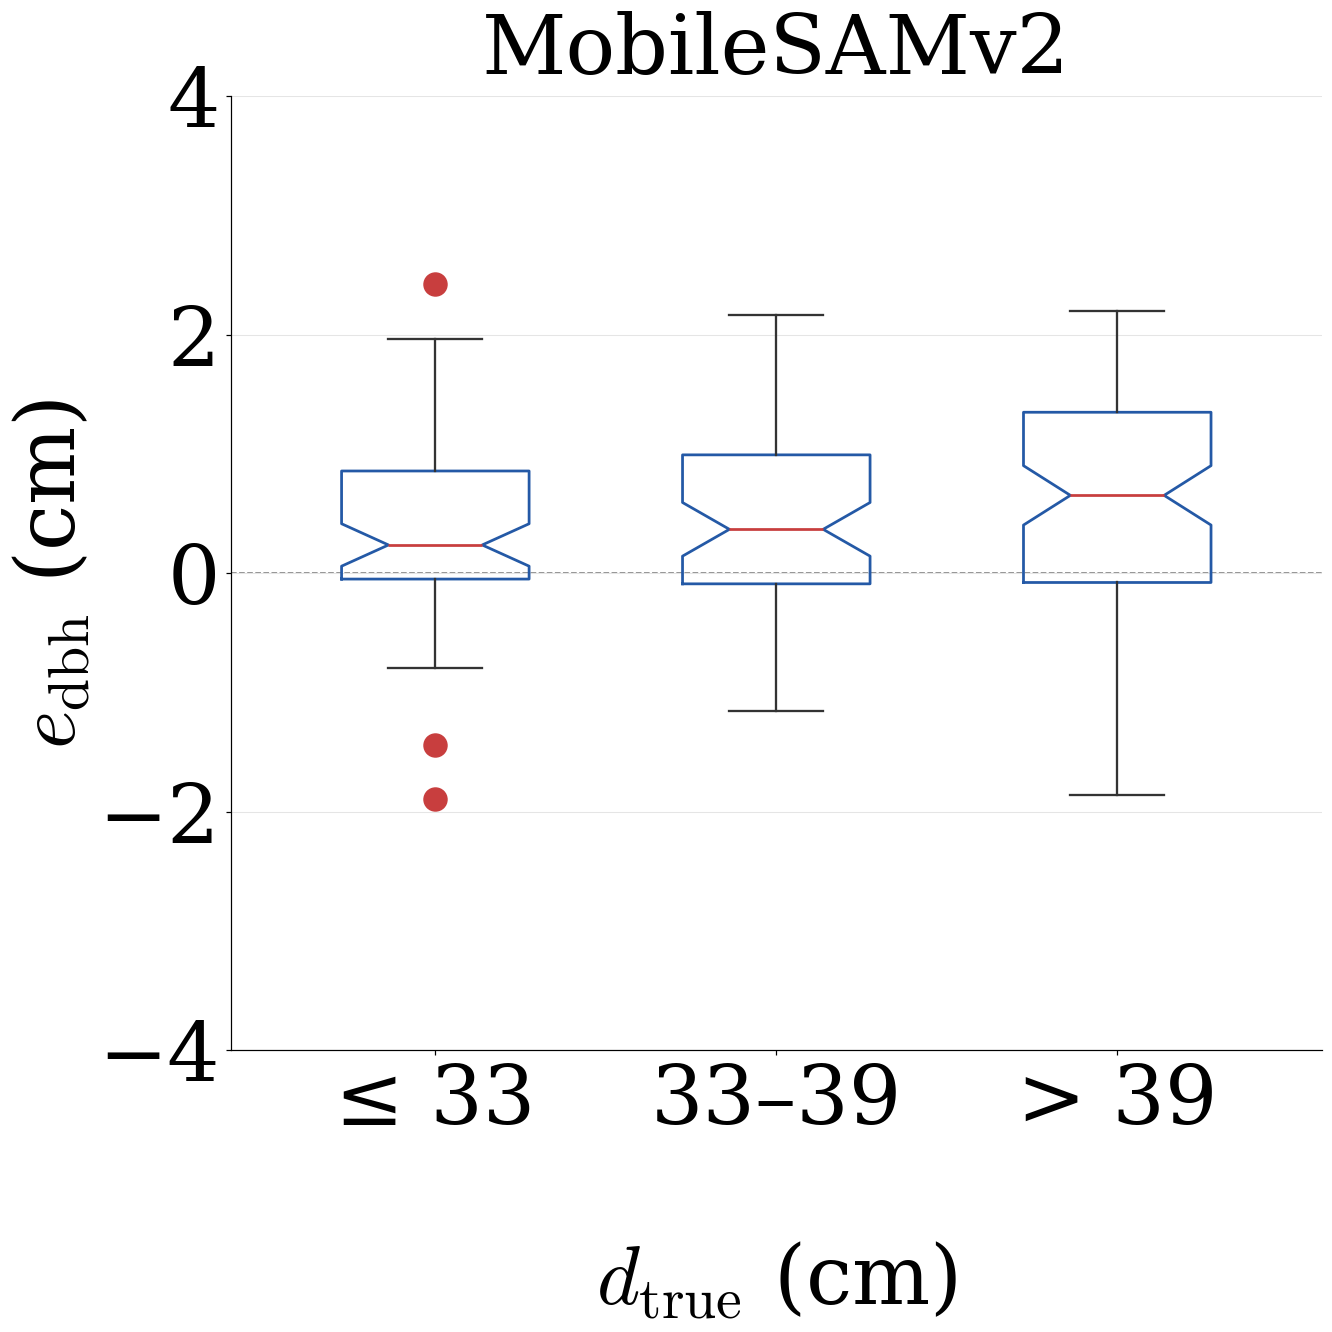

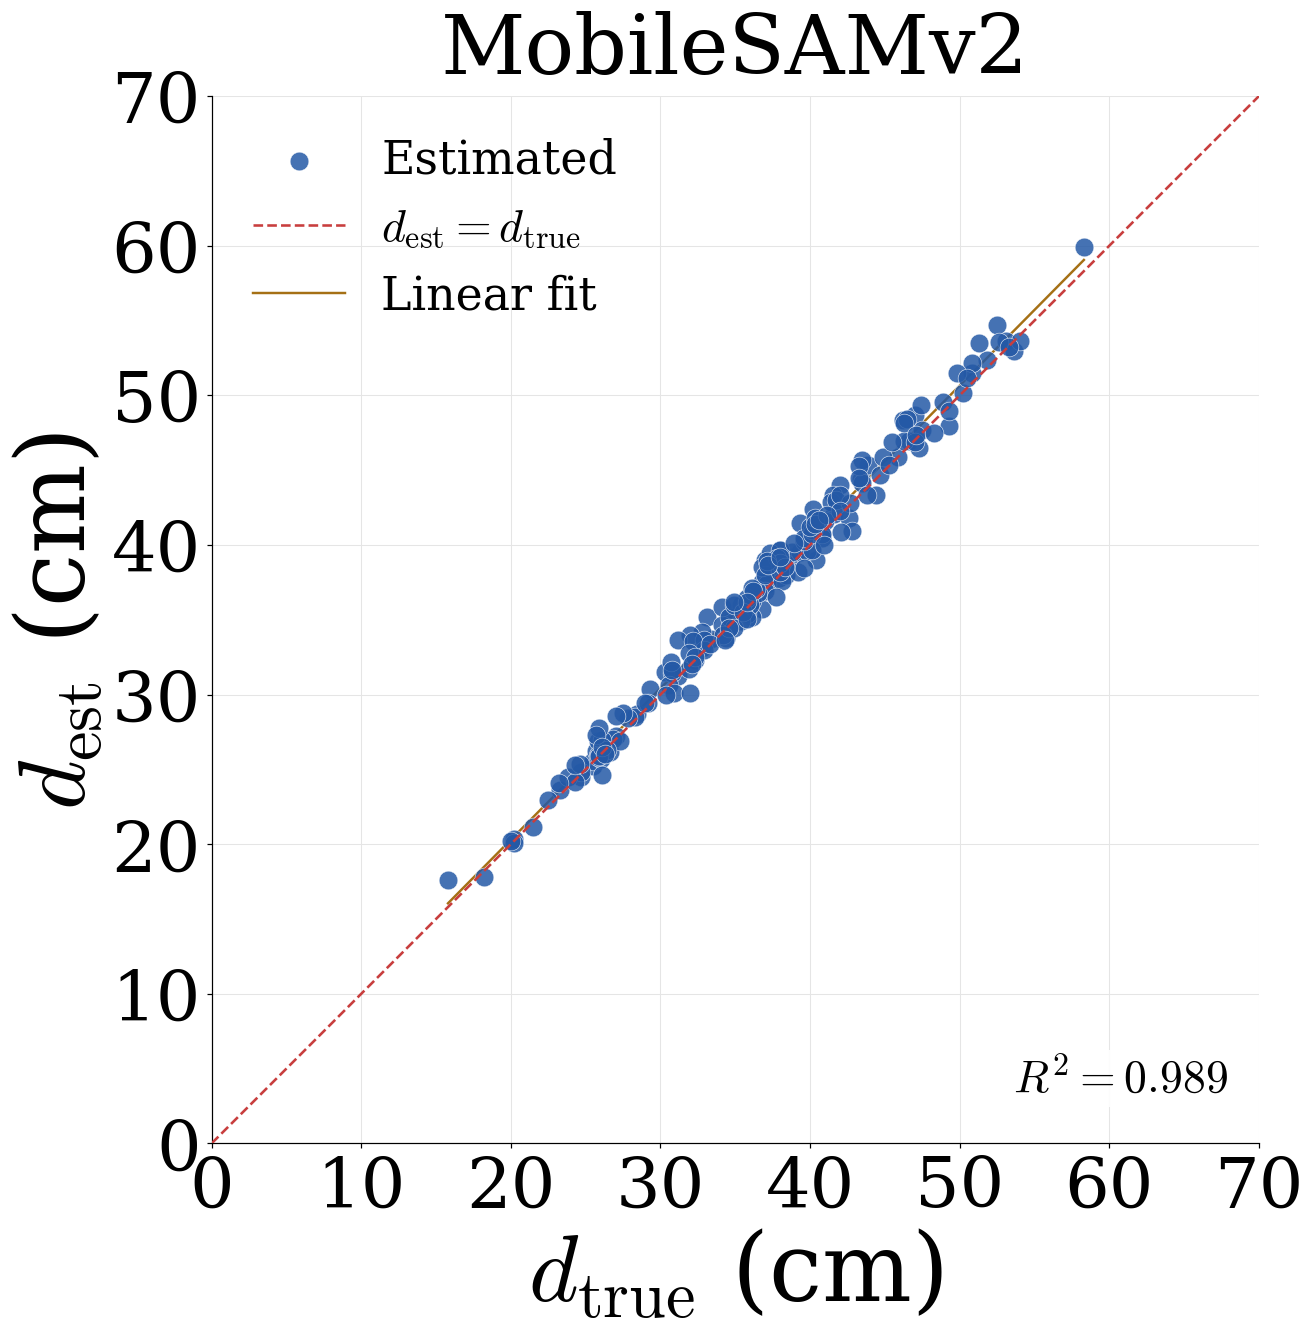

MobileSAMv2 · Plotted: all data: 202/202 rows retained


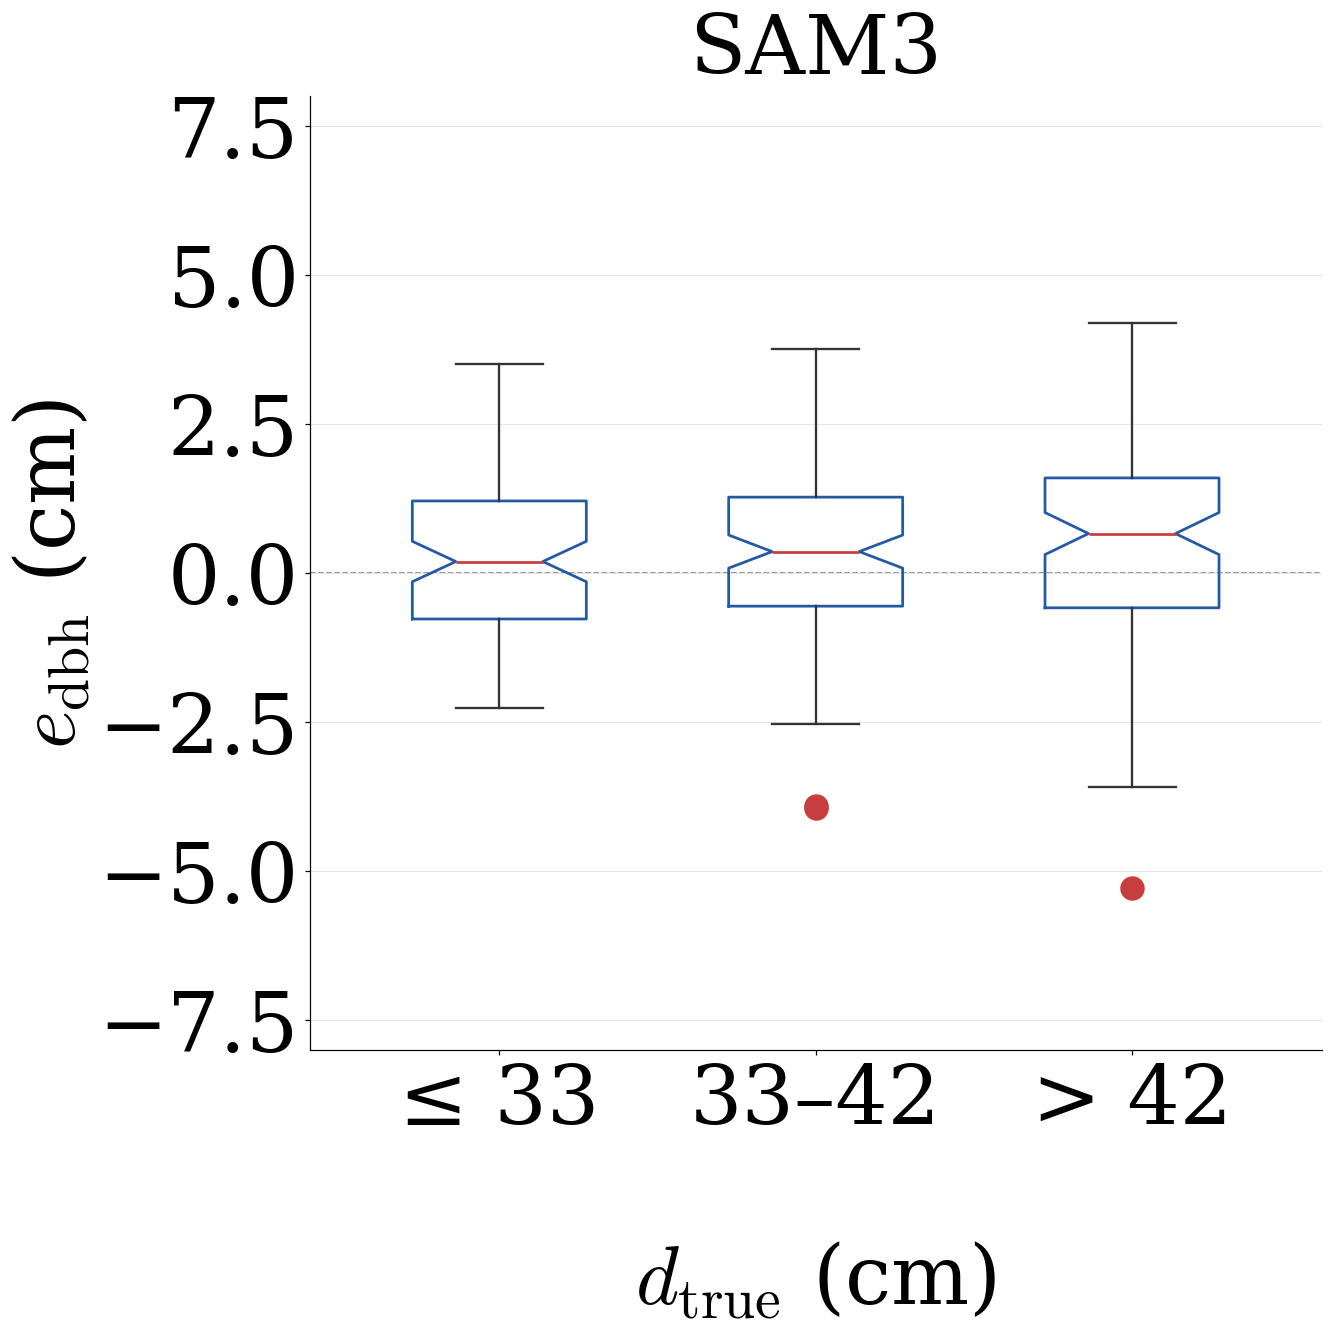

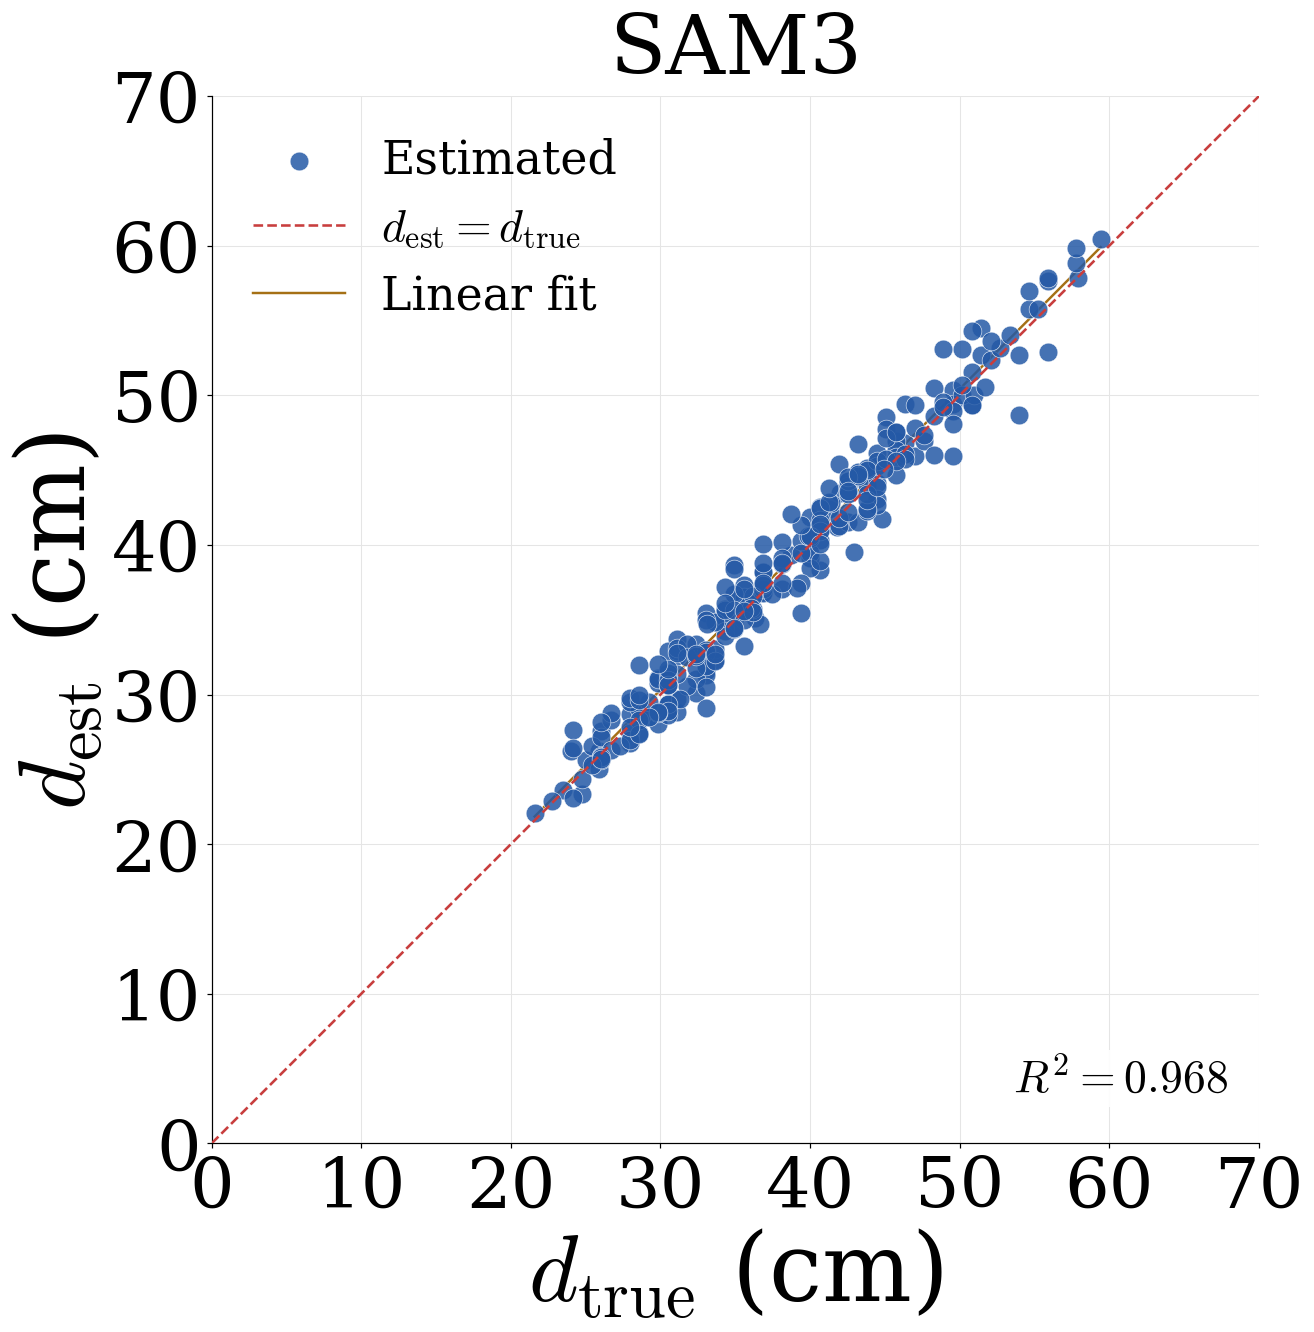

SAM3 · Natural: all data: 285/285 rows retained


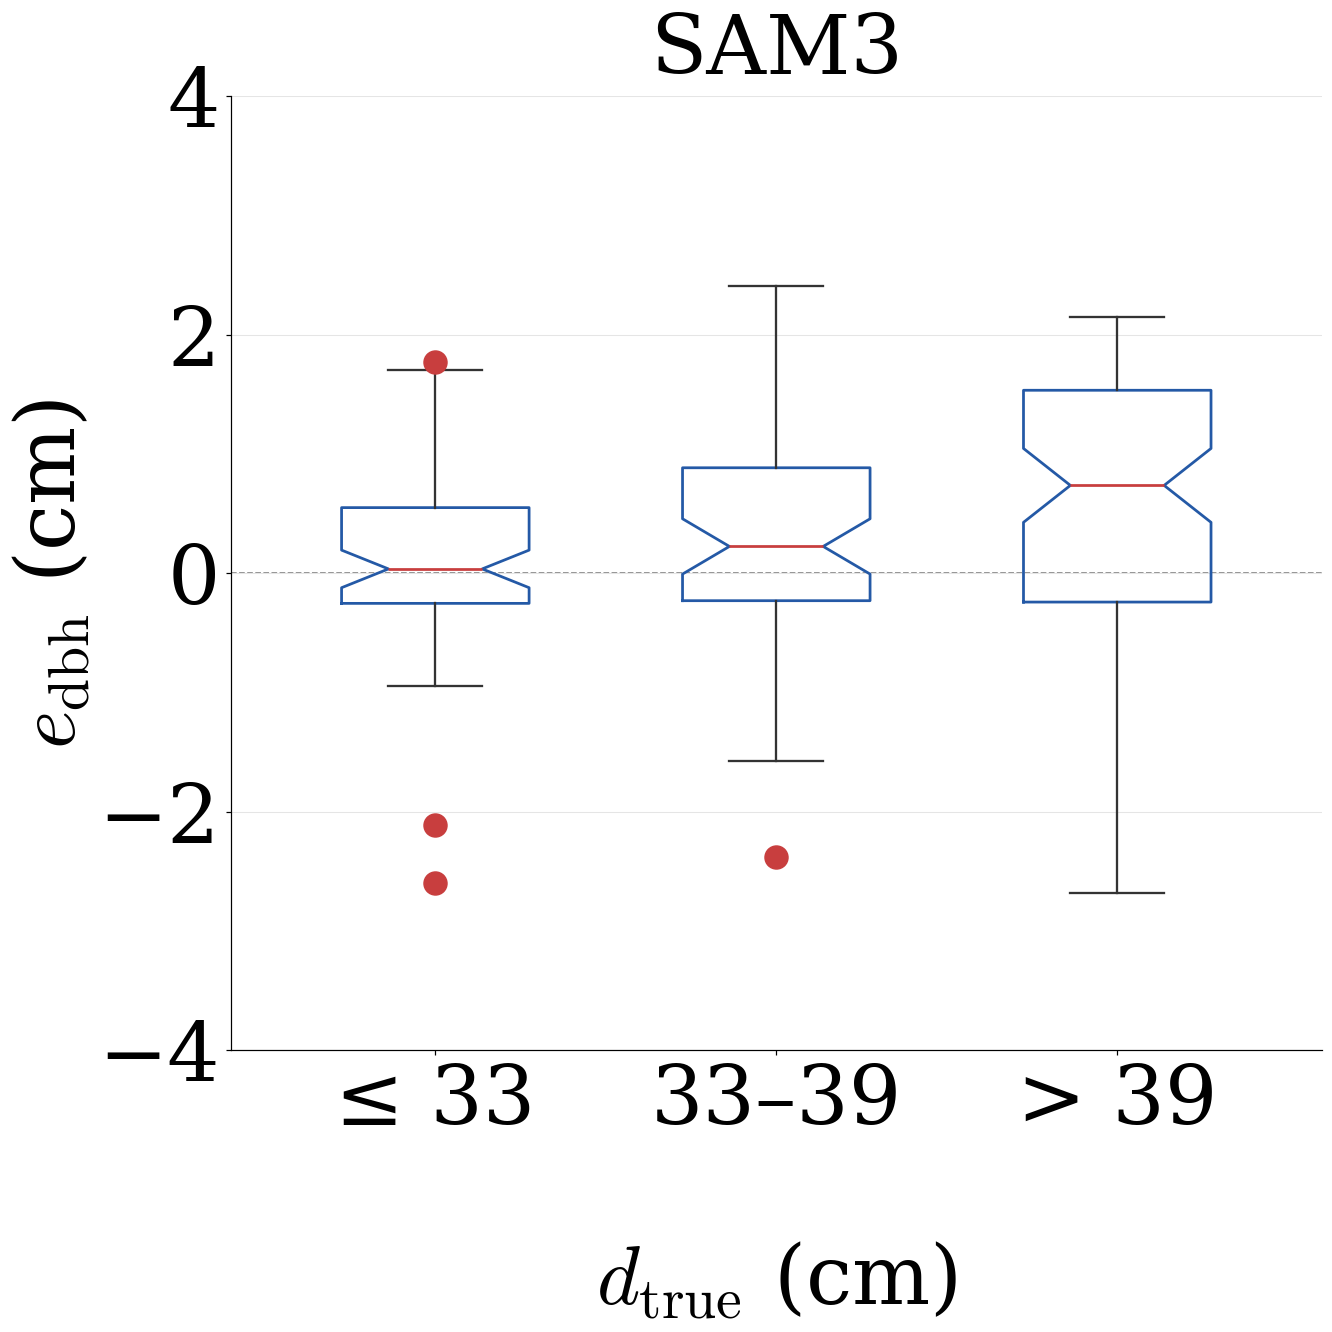

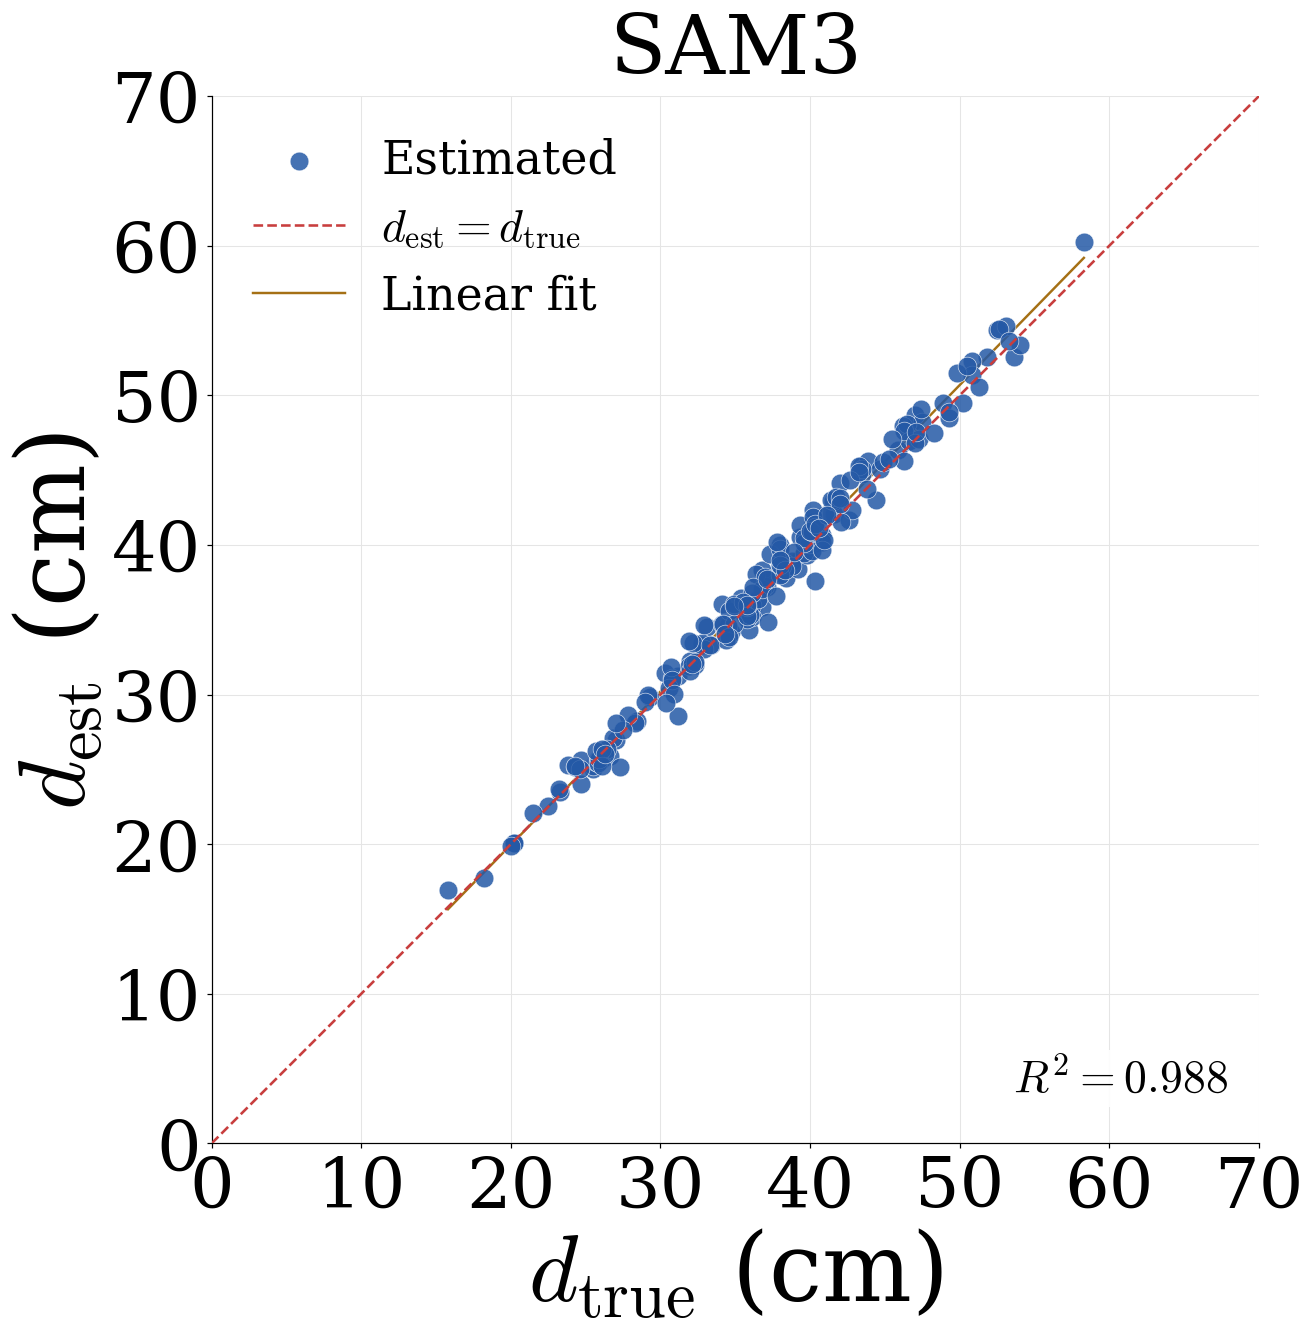

SAM3 · Plotted: all data: 202/202 rows retained

Saved 5 cases to C:\Users\yinzh\OneDrive\桌面\dataDBH\DBH-pipeline-whole\visualization\outputs
Overall statistics (error metrics in cm; R² unitless; population error SD)


,case_id,n,rmse_cm,signed_mean_error_cm,error_std_cm,r2
0,mobilesamv2_natural_whole,285,7.0047,1.3182,6.8795,0.5837
1,mobilesamv2_natural_cleaned,283,1.9183,0.8112,1.7384,0.9594
2,mobilesamv2_plot,202,1.0196,0.4940,0.8920,0.9885
3,sam3_natural,285,1.5346,0.3551,1.4930,0.9685
4,sam3_plot,202,1.0082,0.3618,0.9411,0.9879


Overall and diameter-group statistics


,case_id,group,n,rmse_cm,signed_mean_error_cm,error_std_cm,r2
0,mobilesamv2_natural_whole,Overall,285,7.0047,1.3182,6.8795,0.5837
1,mobilesamv2_natural_whole,≤ 33,84,11.8051,1.8018,11.6668,0.1018
2,mobilesamv2_natural_whole,33 < d ≤ 42,107,4.1932,1.1444,4.0340,0.4036
3,mobilesamv2_natural_whole,> 42,94,2.0523,1.0840,1.7427,0.8606
4,mobilesamv2_natural_cleaned,Overall,283,1.9183,0.8112,1.7384,0.9594
5,mobilesamv2_natural_cleaned,≤ 33,83,1.9569,0.5377,1.8815,0.6247
6,mobilesamv2_natural_cleaned,33 < d ≤ 42,106,1.7582,0.7834,1.5740,0.7701
7,mobilesamv2_natural_cleaned,> 42,94,2.0523,1.0840,1.7427,0.8606
8,mobilesamv2_plot,Overall,202,1.0196,0.4940,0.8920,0.9885
9,mobilesamv2_plot,≤ 33,64,0.8718,0.4009,0.7742,0.9635


Observation counts and exclusions


,case_id,n_input,n_retained,n_excluded_total,n_invalid_pair,n_excluded_by_id
0,mobilesamv2_natural_whole,285,285,0,0,0
1,mobilesamv2_natural_cleaned,285,283,2,0,2
2,mobilesamv2_plot,202,202,0,0,0
3,sam3_natural,285,285,0,0,0
4,sam3_plot,202,202,0,0,0


In [7]:
report = run_all_cases(
    cases=CASES, output_dir=OUTPUT_DIR, selected=SELECTED_CASES,
    options=PROCESSING, style=STYLE, show=SHOW_FIGURES,
    include_raw_diagnostics=INCLUDE_RAW_DIAGNOSTICS, raw_csv=RAW_NATURAL_CSV,
)

print("Overall statistics (error metrics in cm; R² unitless; population error SD)")
display(report["overall"][[
    "case_id", "n", "rmse_cm", "signed_mean_error_cm", "error_std_cm", "r2"
]].round(4))
print("Overall and diameter-group statistics")
display(report["statistics"][[
    "case_id", "group", "n", "rmse_cm", "signed_mean_error_cm", "error_std_cm", "r2"
]].round(4))
print("Observation counts and exclusions")
display(report["counts"][[
    "case_id", "n_input", "n_retained", "n_excluded_total", "n_invalid_pair", "n_excluded_by_id"
]])


## Output files

- `all_cases_statistics.csv`: 20 rows, overall plus three diameter groups for five views.
- `all_cases_overall.csv`: five overall rows with the three error metrics and fitted-line R².
- `all_cases_counts.csv`: retained, excluded, and invalid counts.
- `all_cases_configuration.json`: full-precision settings, input hashes, and versions.
- Each case folder contains statistics, all-row inclusion audits, scatter plots,
  and signed-error boxplots in PNG and PDF.

The publication helper also writes `summary_statistics.csv`, pooled statistics,
and `index.html`. No raw production result is filtered or replaced by a subset.
Filtered MobileSAMv2 results must be interpreted alongside the all-data results.
The single plotted MobileSAMv2 view contains all 202 observations.


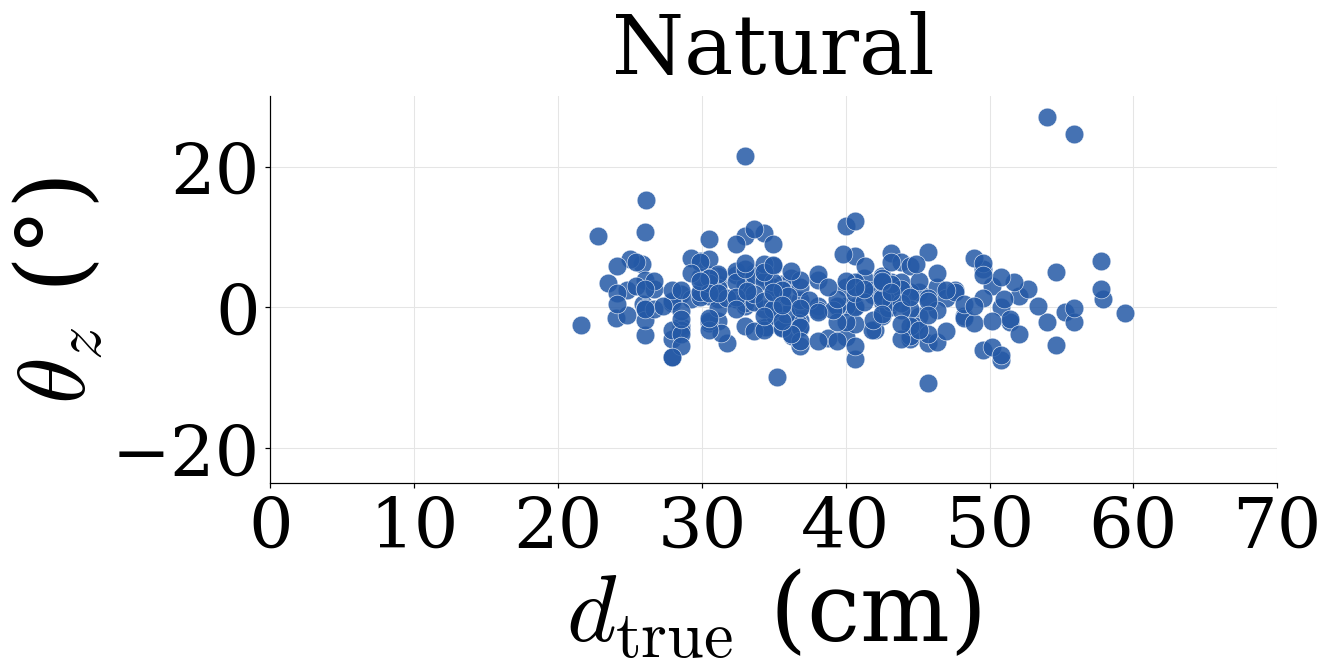

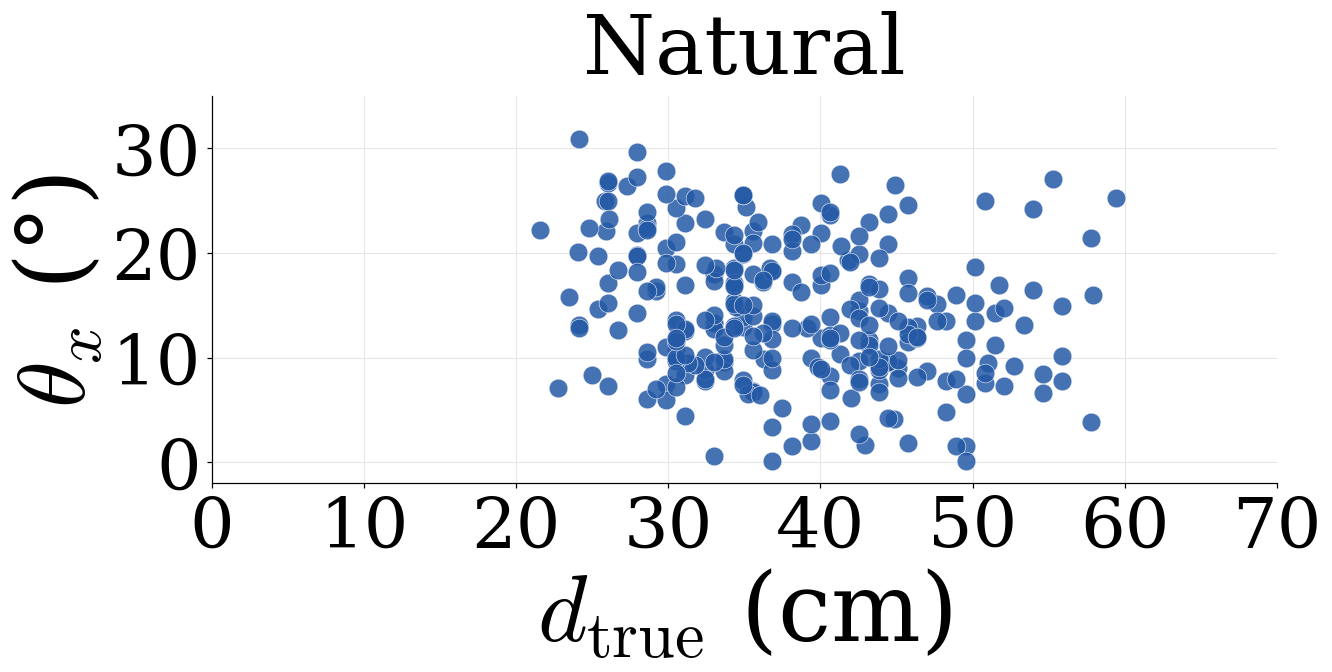

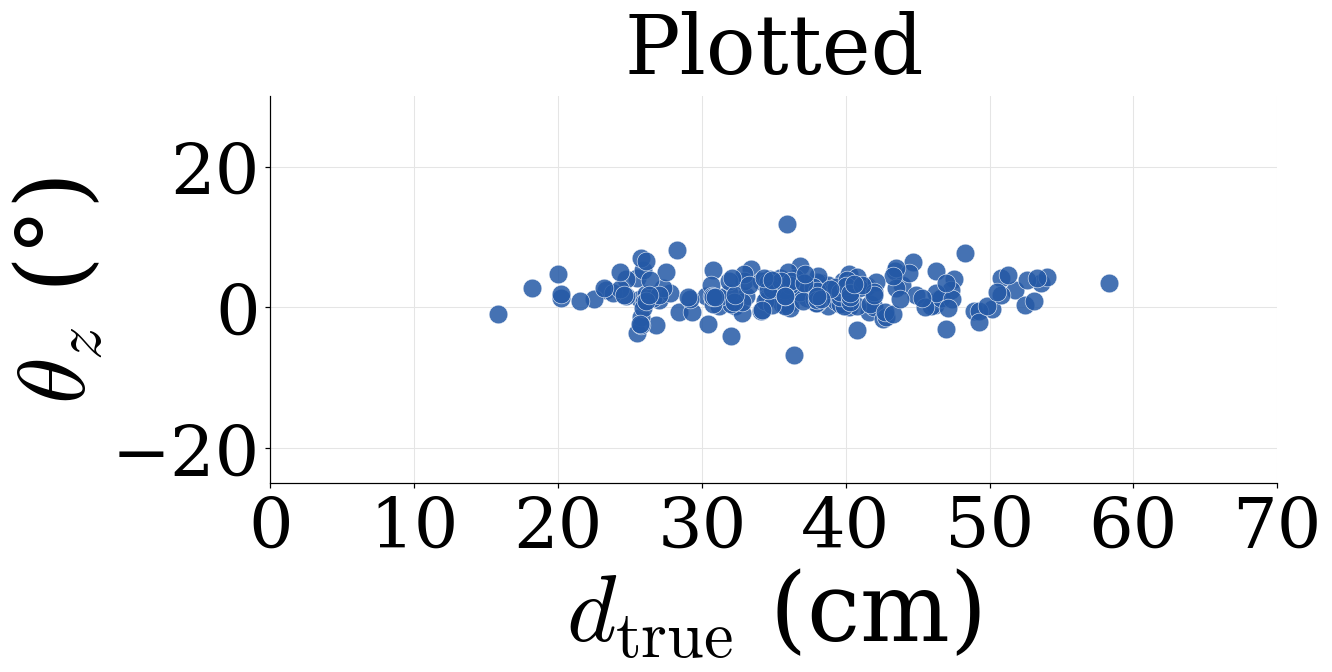

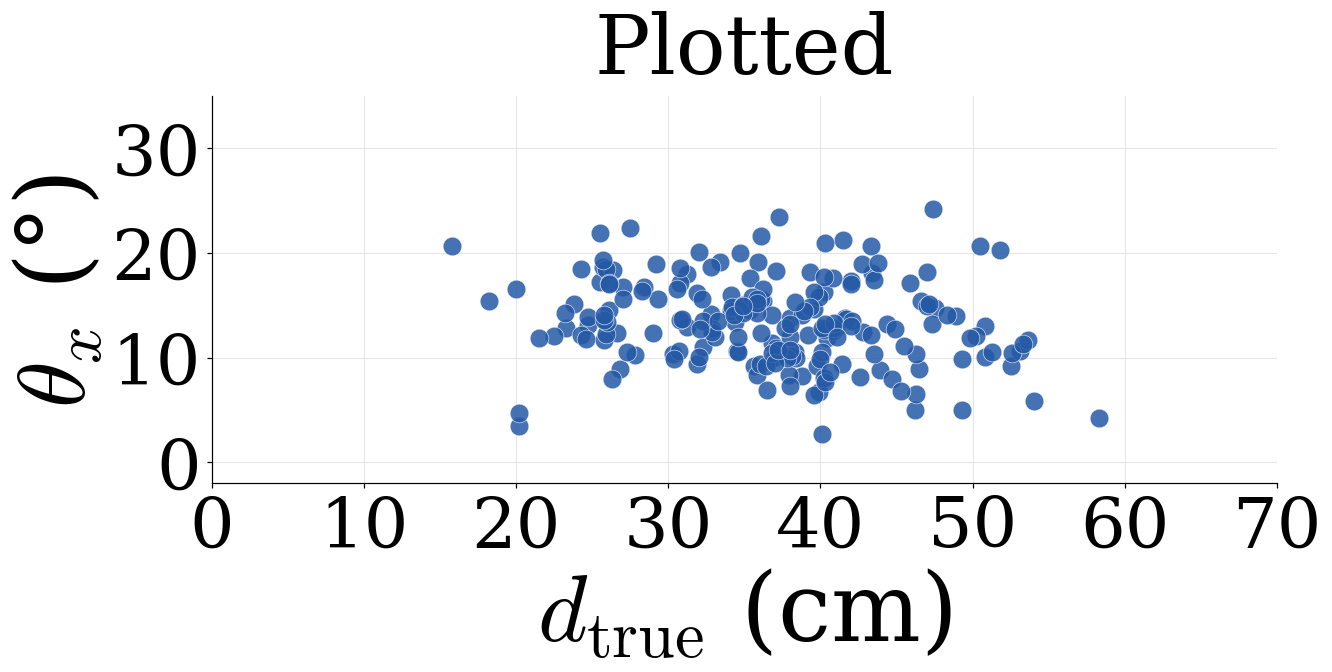

,dataset,variable,n_input,n_plotted,n_invalid
0,Natural,theta_z_deg,285,285,0
1,Natural,theta_x_deg,285,285,0
2,Plotted,theta_z_deg,202,202,0
3,Plotted,theta_x_deg,202,202,0


In [8]:
def plot_rawdata_property(csv_path, dataset, output_dir, style=STYLE, show=True):
    csv_path = Path(csv_path)
    direction_cols = ["growthDirXYZ_x", "growthDirXYZ_y", "growthDirXYZ_z"]
    raw = pd.read_csv(csv_path, dtype={ID_COL: "string"})
    required = {ID_COL, TRUE_COL, *direction_cols}
    missing = required.difference(raw.columns)
    if missing:
        raise ValueError(f"{csv_path}: missing columns {sorted(missing)}")
    if raw[ID_COL].isna().any() or raw[ID_COL].duplicated().any():
        raise ValueError(f"{csv_path}: observation IDs must be present and unique.")
    raw = raw[[ID_COL, TRUE_COL, *direction_cols]].copy()
    raw[[TRUE_COL, *direction_cols]] = raw[[TRUE_COL, *direction_cols]].apply(
        pd.to_numeric, errors="coerce")
    a, b, c = raw[direction_cols].to_numpy(dtype=float).T
    valid_direction = np.isfinite(raw[direction_cols]).all(axis=1).to_numpy()
    valid_reference = np.isfinite(raw[TRUE_COL]) & (raw[TRUE_COL] > 0)
    for column, numerator in [("theta_z_deg", a), ("theta_x_deg", c)]:
        angle = np.degrees(np.arctan2(numerator, b))
        angle = np.where(angle > 90, angle - 180,
                         np.where(angle < -90, angle + 180, angle))
        valid_projection = valid_direction & ((numerator != 0) | (b != 0))
        raw[column] = np.where(valid_projection, angle, np.nan)
        raw[f"{column}_plotted"] = valid_reference & valid_projection
    destination = Path(output_dir) / dataset.lower()
    destination.mkdir(parents=True, exist_ok=True)
    raw.to_csv(destination / "angles.csv", index=False, encoding="utf-8-sig")
    records = []
    for column, stem, ylabel, preferred in [
        ("theta_z_deg", "theta_z", r"$\theta_z$ (°)", (-25, 30)),
        ("theta_x_deg", "theta_x", r"$\theta_x$ (°)", (-2, 35)),
    ]:
        pairs = raw.loc[raw[f"{column}_plotted"]]
        if pairs.empty:
            raise ValueError(f"{csv_path}: no valid observations for {column}.")
        with plt.rc_context(plot_rc(style)):
            fig, ax = plt.subplots(figsize=(12, 6), layout="constrained")
            ax.scatter(pairs[TRUE_COL], pairs[column], s=150, color=style.color,
                       edgecolors="white", linewidths=0.4, alpha=0.85, zorder=3)
            ax.set_xlabel(r"$d_{\mathrm{true}}$ (cm)", fontsize=style.font_size + 8)
            ax.set_ylabel(ylabel, fontsize=style.font_size + 8)
            ax.set_title(dataset, pad=15, fontsize=style.font_size)
            ax.set_xlim(*expanded_limits(pairs[TRUE_COL], (0, 70)))
            ax.set_ylim(*preferred)
            ax.xaxis.set_major_locator(MaxNLocator(nbins=7))
            ax.yaxis.set_major_locator(MultipleLocator(10 if stem == "theta_x" else 20))
            ax.grid(True, color="#E5E5E5", linewidth=0.7)
            ax.set_axisbelow(True)
        save_figure(fig, destination / stem, style, show)
        records.append({"dataset": dataset, "variable": column, "n_input": len(raw),
                        "n_plotted": len(pairs), "n_invalid": len(raw) - len(pairs),
                        "source_csv": str(csv_path.resolve()),
                        "source_sha256": hashlib.sha256(csv_path.read_bytes()).hexdigest()})
    return pd.DataFrame(records)


RAWDATA_PROPERTY_DIR = OUTPUT_DIR / "rawdata_property"
MOBILE_RAWDATA_PROPERTY_DIR = RAWDATA_PROPERTY_DIR / "MobileSAMv2"
MOBILE_RAWDATA_PROPERTY_INPUTS = {
    "Natural": DATA_DIR / "MobileSAMv2" / "results_MobileSAMv2_natural.csv",
    "Plotted": DATA_DIR / "MobileSAMv2" / "results_MobileSAMv2_plot.csv",
}
mobile_rawdata_property_counts = pd.concat([
    plot_rawdata_property(csv_path, dataset, MOBILE_RAWDATA_PROPERTY_DIR, STYLE, SHOW_FIGURES)
    for dataset, csv_path in MOBILE_RAWDATA_PROPERTY_INPUTS.items()
], ignore_index=True)
mobile_rawdata_property_counts.to_csv(
    MOBILE_RAWDATA_PROPERTY_DIR / "counts.csv", index=False, encoding="utf-8-sig")
display(mobile_rawdata_property_counts[["dataset", "variable", "n_input", "n_plotted", "n_invalid"]])

